Y coordinates identical: True
X coordinates identical: True
Max |y difference|: 0.0
Max |x difference|: 0.0
-1.0630068
0.0
-0.72287923
0.16184999


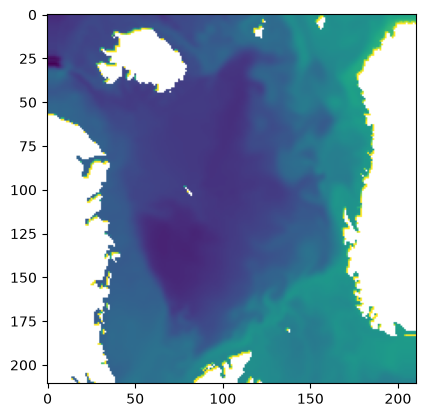

In [12]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
ds = xr.open_zarr("./data/nemo_ocean.zarr")
ds_forcing = xr.open_zarr("./data/nemo_forcing.zarr")

print("Y coordinates identical:",
      np.array_equal(ds.y.values, ds_forcing.y.values))

print("X coordinates identical:",
      np.array_equal(ds.x.values, ds_forcing.x.values))

print("Max |y difference|:",
      np.max(np.abs(ds.y.values - ds_forcing.y.values)))

print("Max |x difference|:",
      np.max(np.abs(ds.x.values - ds_forcing.x.values)))

ssh = ds["ssh"][50]
msl = ds_forcing["msl"][0]
u10 = ds_forcing["u10"][0]
v10 = ds_forcing["v10"][0]

print(np.nanmin(ssh))
print(np.nanmax(ssh))
print(np.nanmean(ssh))
print(np.nanstd(ssh))

plt.Figure()
plt.imshow(ssh)



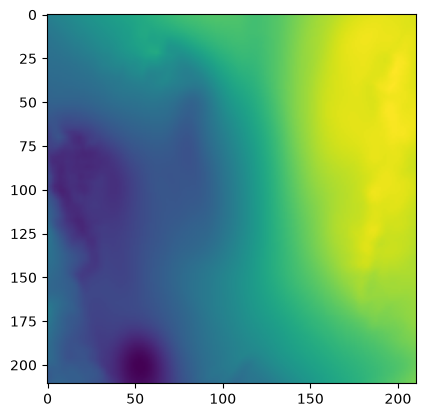

In [13]:
plt.Figure()
plt.imshow(msl)

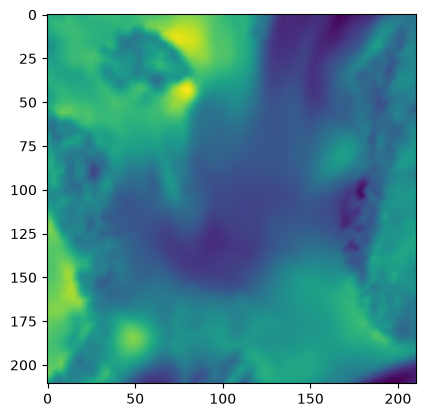

In [14]:
plt.Figure()
plt.imshow(u10)

c:\Users\esthe\anaconda3\envs\preprocess\Lib\site-packages\cartopy\io\__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


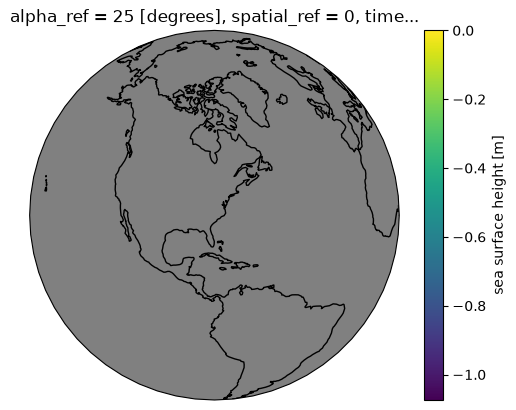

In [ ]:
import cartopy.crs as ccrs

p = ssh.plot(
    subplot_kws=dict(projection=ccrs.Orthographic(-, 35), facecolor="gray"),
    transform=ccrs.PlateCarree(),
)
p.axes.set_global()

p.axes.coastlines();

# FNO implementation
1980 -2026 \
inputs: SSH, u_curr, v_curr, SLP, u_wind, v_wind, bathy \
outputs: SSH_(t+Δt), u_curr_(t+Δt), v_curr_(t+Δt)

## Import necessary lib

In [10]:
import torch
import torch.nn as nn
import torch.fft
import matplotlib.pyplot as plt
import numpy as np
import os
#from neuralop.models import FNO
import xarray as xr

['bathy_metry', 'lat', 'lon', 'y', 'x', 'crs', 'alpha_ref']


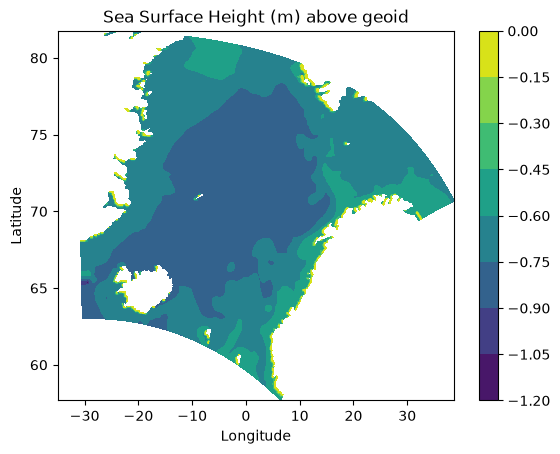

: 

In [ ]:

dmn = np.load("data/nemo_bathymetry.npz")

print(dmn.files)

plt.contourf(dmn["lon"],  dmn["lat"], ssh)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Sea Surface Height (m) above geoid")
plt.colorbar()

In [2]:
data_era5 = xr.open_mfdataset(f'processed\\forcing_1980_01-1980_01.nc')
data1 = xr.open_mfdataset(f'processed\\mask_1980_01-1980_01.nc')
data2 = xr.open_mfdataset(f'processed\\state_1980_01-1980_01.nc')
print(data_era5.dims)
print("Dataset attrs:", data_era5.attrs)
print("Coordinates:", list(data_era5.coords))
print(data1.dims)
print("Dataset attrs:", data1.attrs)
print("Coordinates:", list(data1.coords))
print(data1.dims)
print("Dataset attrs:", data2.attrs)
print("Coordinates:", list(data2.coords))

FrozenMappingWarningOnValuesAccess({'time': 124, 'y': 280, 'x': 230, 'channel': 3})
Dataset attrs: {}
Coordinates: ['time', 'time_centered', 'channel']
FrozenMappingWarningOnValuesAccess({'y': 280, 'x': 230})
Dataset attrs: {}
Coordinates: ['nav_lat', 'nav_lon']
FrozenMappingWarningOnValuesAccess({'y': 280, 'x': 230})
Dataset attrs: {}
Coordinates: ['channel', 'time_centered', 'time', 'nav_lat', 'nav_lon']


In [7]:
forcings = {}
#for year in range(1980):
    
    #data_forcing_feb = xr.open_dataset(f'data\\forcing\\fno_ERA5forcing_y{year}m02.nc')
    #data_forcing_mar = xr.open_dataset(f'data\\forcing\\fno_ERA5forcing_y{year}m03.nc')
    #data_forcing_apr = xr.open_dataset(f'data\\forcing\\fno_ERA5forcing_y{year}m04.nc')
    #data_forcing_may = xr.open_dataset(f'data\\forcing\\fno_ERA5forcing_y{year}m05.nc')
    #data_forcing_jun = xr.open_dataset(f'data\\forcing\\fno_ERA5forcing_y{year}m06.nc')
    #data_forcing_jul = xr.open_dataset(f'data\\forcing\\fno_ERA5forcing_y{year}m07.nc')
    #data_forcing_aug = xr.open_dataset(f'data\\forcing\\fno_ERA5forcing_y{year}m08.nc')
    #data_forcing_sep = xr.open_dataset(f'data\\forcing\\fno_ERA5forcing_y{year}m09.nc')
    #data_forcing_oct = xr.open_dataset(f'data\\forcing\\fno_ERA5forcing_y{year}m10.nc')
    #data_forcing_nov = xr.open_dataset(f'data\\forcing\\fno_ERA5forcing_y{year}m11.nc')
    #data_forcing_dec = xr.open_dataset(f'data\\forcing\\fno_ERA5forcing_y{year}m12.nc')
    #forcings[year] = (data_forcing_
    #jan, data_forcing_feb, data_forcing_mar, data_forcing_apr, data_forcing_may, data_forcing_jun, data_forcing_jul, data_forcing_aug, data_forcing_sep, data_forcing_oct, data_forcing_nov, data_forcing_dec)

data_era5 = xr.open_mfdataset(f'data\\fno_ERA5forcing*.nc')
data_msl = xr.open_mfdataset(f'data\\fno_ERA5forcing*.nc')
data_u = xr.open_mfdataset(f'data\\fno_ERA5forcing*.nc')["u10"]
data_v = xr.open_mfdataset(f'data\\fno_ERA5forcing*.nc')["v10"]

# msl_feb_1980 = data_forcing_feb["msl"]
# u10_feb_1980 = data_forcing_feb["u10"]
# v10_feb_1980 = data_forcing_feb["v10"]
# msl_mar_1980 = data_forcing_mar["msl"]
# u10_mar_1980 = data_forcing_mar["u10"]
# v10_mar_1980 = data_forcing_mar["v10"]
# msl_apr_1980 = data_forcing_apr["msl"]
# u10_apr_1980 = data_forcing_apr["u10"]
# v10_apr_1980 = data_forcing_apr["v10"]
# msl_may_1980 = data_forcing_may["msl"]
# u10_may_1980 = data_forcing_may["u10"]
# v10_may_1980 = data_forcing_may["v10"]
# msl_jun_1980 = data_forcing_jun["msl"]
# u10_jun_1980 = data_forcing_jun["u10"]
# v10_jun_1980 = data_forcing_jun["v10"]
# msl_jul_1980 = data_forcing_jul["msl"]
# u10_jul_1980 = data_forcing_jul["u10"]
# v10_jul_1980 = data_forcing_jul["v10"]
# msl_aug_1980 = data_forcing_aug["msl"]
# u10_aug_1980 = data_forcing_aug["u10"]
# v10_aug_1980 = data_forcing_aug["v10"]

# data_forcing_feb_1983 = xr.open_dataset('data\\forcing\\fno_ERA5forcing_y1983m01.nc')

data_ssh = xr.open_mfdataset('data\\*ssh.nc') # Sea surface height
data_ubar = xr.open_mfdataset('data\\*ubar.nc') # U
data_vbar = xr.open_mfdataset('data\\*vbar.nc') # V
data_bath = xr.open_dataset('data\\nordic_seas_domain_cfg.nc')


#forcings[1980][0]
print(data_bath.values)
print("Dataset attrs:", data_bath.attrs)
print("Coordinates:", list(data_bath.coords))
print("Variables:", list(data_bath.data_vars))
print(data_bath["bathy_metry"])
print("bathy_metry attrs:", data_bath["bathy_metry"].attrs)

#print(data_msl)
# print(data_ssh.dims)
# print("Dataset attrs:", data_ssh.attrs)
# print("Coordinates:", list(data_ssh.coords))

#print(data_ubar.dims)
#print("Dataset attrs:", data_ubar.attrs)
#print("Coordinates:", list(data_ubar.coords))

#print(data_vbar.dims)
#print("Dataset attrs:", data_vbar.attrs)
#print("Coordinates:", data_msl.dims)
#print("Variables:", list(data_ssh.data_vars))
# print(data_ssh["ssh"])
# print("bathy_metry attrs:", data_ssh["ssh"].attrs)

#print(u10_jan_1980)
#print("Dataset attrs:", data_forcing_jan.attrs)
#print("Coordinates:", list(data_forcing_jan.coords))
#print("Variables:", list(data_forcing_jan.data_vars))
# print(data_ssh)
# print(data_ubar)
# print(data_vbar)
# print(msl_jan_1980)


print(np.unique(data_bath["bottom_level"]))
print(np.unique(data_bath["top_level"]))
print(np.unique(data_bath["bathy_metry"])) #the depth of the ocean




OSError: no files to open

In [4]:
print(data_bath["top_level"].isnull().sum())
print(data_ssh["ssh"].isnull().sum())



<xarray.DataArray 'top_level' ()> Size: 8B
array(0)
Attributes:
    long_name:  top_level
    units:      -
<xarray.DataArray 'ssh' ()> Size: 8B
dask.array<sum-aggregate, shape=(), dtype=int64, chunksize=(), chunktype=numpy.ndarray>
Attributes:
    standard_name:       sea_surface_height_above_geoid
    long_name:           sea surface height
    units:               m
    online_operation:    average
    interval_operation:  600 s
    interval_write:      1 h
    cell_methods:        time: mean (interval: 600 s)


In [5]:
ssh = data_ssh["ssh"]

has_nan = bool(ssh.isnull().any().compute())
print("SSH has NaN values:", has_nan)

# optional: how many
nan_count = int(ssh.isnull().sum().compute())
print("NaN count:", nan_count)

SSH has NaN values: True
NaN count: 211260600


In [6]:
lat_min = float(data_ssh['ssh'].nav_lat.min())
lat_max = float(data_ssh['ssh'].nav_lat.max())

lon_min = float(data_ssh['ssh'].nav_lon.min())
lon_max = float(data_ssh['ssh'].nav_lon.max())

print(data_era5.lon.min().item(), data_era5.lon.max().item())
print(float(lon_min), float(lon_max))

-180.0 179.75
-42.09150314331055 45.71455764770508


In [7]:
print(data_ssh.dims)
print(data_ubar.dims)
print(data_vbar.dims)

FrozenMappingWarningOnValuesAccess({'time_counter': 35064, 'axis_nbounds': 2, 'y': 280, 'x': 230})
FrozenMappingWarningOnValuesAccess({'time_counter': 8784, 'axis_nbounds': 2, 'y': 280, 'x': 230})
FrozenMappingWarningOnValuesAccess({'time_counter': 8784, 'axis_nbounds': 2, 'y': 280, 'x': 230})


In [8]:
import psutil

ram = psutil.virtual_memory()

print(f"Total RAM: {ram.total / (1024**3):.2f} GB")
print(f"Available RAM: {ram.available / (1024**3):.2f} GB")
print(f"Used RAM: {ram.used / (1024**3):.2f} GB")

Total RAM: 15.69 GB
Available RAM: 0.66 GB
Used RAM: 15.03 GB


In [9]:
# land_mask = torch.tensor(data_bath['top_level'].values, dtype=torch.float)



# # masking with bottomlevel
# ssh = ssh_np.where(land_mask == 1, 0)
# ubar = ubar_np.where(land_mask == 1, 0)
# vbar = vbar_np.where(land_mask == 1, 0)


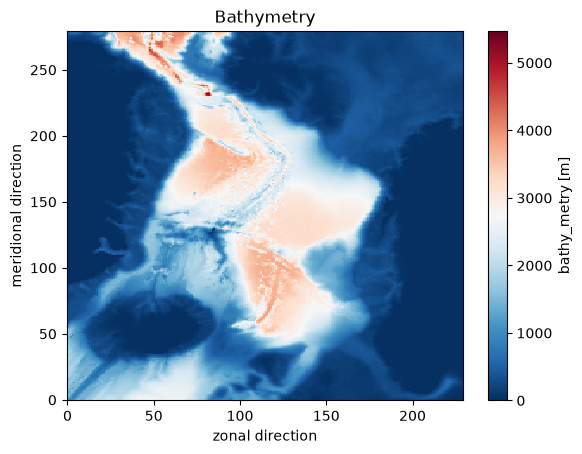

In [10]:
# Bathymetry is the depth of the ocean.
da = data_bath["bathy_metry"]
img = da.plot(cmap="RdBu_r", add_colorbar=True)

#.plot()
plt.xlabel("zonal direction")
plt.ylabel("meridional direction")
plt.title("Bathymetry")
plt.show()

In [6]:
lat_2 = torch.tensor(data_bath['nav_lat'].values, dtype=torch.float)
lon_2 = torch.tensor(data_bath['nav_lon'].values, dtype=torch.float)

plt.Figure()
plt.contourf(lon_2, lat_2, data_bath["bathy"])
plt.colorbar(label='bathymetry (m)')

NameError: name 'torch' is not defined

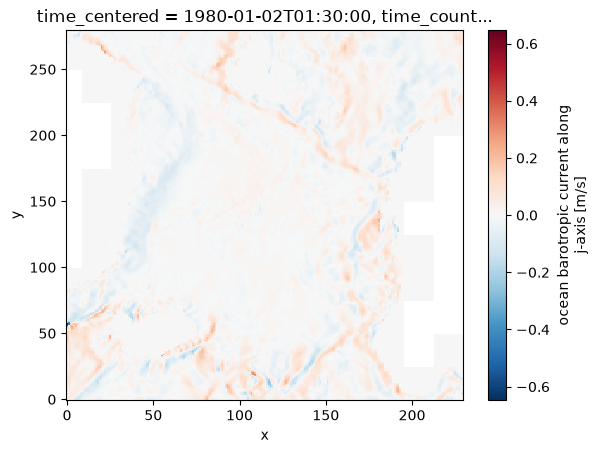

In [12]:
from matplotlib.colors import TwoSlopeNorm
da = data_vbar["vbar"].isel(time_counter=25
                            )

maxabs = np.nanmax(np.abs(da.values))
norm = TwoSlopeNorm(vmin=-maxabs, vcenter=0, vmax=maxabs)

img = da.plot(
    cmap="RdBu_r",
    norm=norm,
    add_colorbar=True,
)
#plt.title("meridional barotropic current at time 0")
plt.show()

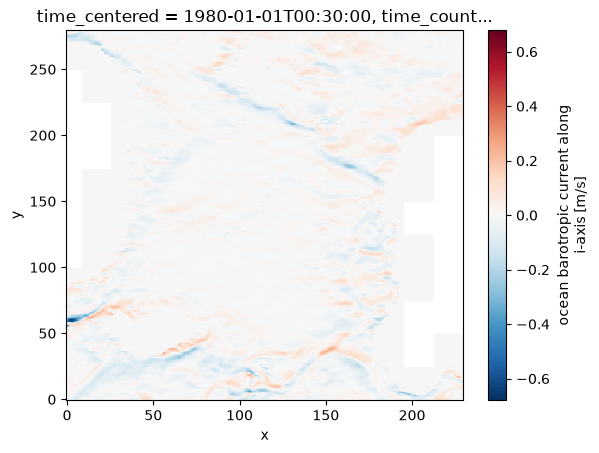

In [13]:
data_ubar["ubar"].isel(time_counter=0).plot()
#plt.title("Zonal barotropic current at time 0")
plt.show()

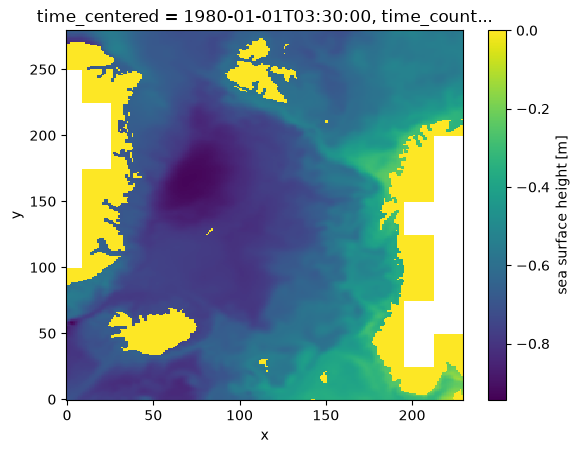

In [14]:
data_ssh["ssh"].isel(time_counter=3).plot()
#plt.title("Sea surface height at time 0")
plt.show()

In [ ]:
ssh_3h = data_ssh.resample(
    time_counter="3h"
).mean()

ubar_3h = data_ubar.resample(
    time_counter="3h"
).mean()

vbar_3h = data_vbar.resample(
    time_counter="3h"
).mean()

vbar_3h.time.size

In [ ]:
ssh_time_mean = data_ssh["ssh"].mean(dim='time_counter', skipna=True)
print(ssh_time_mean)

In [ ]:
lat_min = float(data_ssh.nav_lat.min())
lat_max = float(data_ssh.nav_lat.max())

lon_min = float(data_ssh.nav_lon.min())
lon_max = float(data_ssh.nav_lon.max())

print(lat_min, lat_max)
print(lon_min, lon_max)

In [ ]:
buffer = 5  # degrees

era5_crop = data_era5.sel(
    lat=slice(lat_max + buffer, lat_min - buffer),  # ERA5 latitude decreases
    lon=slice(lon_min - buffer, lon_max + buffer)
)

In [ ]:
print(np.max(np.abs(data_ssh.nav_lon - data_ubar.nav_lon)))
print(np.max(np.abs(data_ssh.nav_lat - data_ubar.nav_lat)))

In [ ]:

plt.rcParams['figure.figsize'] = [8, 4
                                  ]
era5_crop["u10"].isel(time=1).plot(cmap="RdBu_r")
#plt.title("10 metre U wind component")
plt.xlabel("longitude ($\\degree$ E)")
plt.ylabel("latitude ($\\degree$ N)")

plt.show()

In [ ]:
data_era5["v10"].isel(time=1).plot()
plt.show()

In [ ]:
target = data_era5["msl"]
print(target.lat, target.lon)
target.isel(time=1).plot()
plt.show()

In [ ]:
target = data_ssh
print(target["y"], target["x"])

objective: emulating barotropic ocean currents (u, v) and sea surface height (ssh) of the next time step.
inputs: U10, v10, msl, bathymetry, and previous state of the ocean (u, v, ssh)

In [ ]:
forcing_interp_jan = data_forcing_jan.interp(
    lat=data_ssh.nav_lat, 
    lon=data_ssh.nav_lon, 
    method='linear'
)


In [ ]:
# Check actual shapes
print("data_forcing_jan['u10'].shape:", data_forcing_jan['u10'].shape)
print("data_forcing_jan['v10'].shape:", data_forcing_jan['v10'].shape)
print("data_forcing_jan['msl'].shape:", data_forcing_jan['msl'].shape)
print()

print("data_ssh['ssh'].shape:", data_ssh['ssh'].shape)
print("data_ssh['ssh'] variables:", data_ssh['ssh'].dims)
print()
print("data_ubar['ubar'].shape:", data_ubar['ubar'].shape)
print("data_ubar['ubar'] variables:", data_ubar['ubar'].dims)
print()
print("data_vbar['vbar'].shape:", data_vbar['vbar'].shape)
print("data_vbar['vbar'] variables:", data_vbar['vbar'].dims)

In [ ]:
# Instead of concatenating all months in memory at once (MemoryError),
# process each month sequentially and collect the arrays.
months = [data_forcing_jan]

interp_list = []
for ds in months:
    # spatial interpolation for this month
    tmp = ds.interp(lat=data_ssh.nav_lat, lon=data_ssh.nav_lon, method='linear')
    # take only necessary variables and convert to numpy
    arr = np.stack([tmp['u10'].values, tmp['v10'].values, tmp['msl'].values], axis=1)
    # arr shape: (time, 3, y, x)
    interp_list.append(arr)
    print(f"Processed month shape: {arr.shape}")

# concatenate along time axis
forcing_all_np = np.concatenate(interp_list, axis=0)
print("Concatenated forcing array shape", forcing_all_np.shape)

# if desired, you can convert back to xarray later
# forcing_interp = xr.DataArray(forcing_all_np, dims=('time','var','y','x'))

# we'll use forcing_all_np when building inputs
